## Importing Necessary Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


## Load The Dataset

In [ ]:
from google.colab import files
uploaded=files.upload()



Saving parsed_resumes.csv to parsed_resumes (1).csv


In [ ]:
from google.colab import files
uploaded=files.upload()



Saving Data Definition (3).xlsx to Data Definition (3) (1).xlsx


In [ ]:
# Load the candidate resume dataset
df = pd.read_csv("parsed_resumes.csv")

# Load the data dictionary
data_dictionary = pd.read_excel("Data Definition (3).xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Data dictionary shape:", data_dictionary.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5000, 34)
Data dictionary shape: (34, 3)


,candidate_id,resume_file_name,candidate_name,primary_domain,primary_role,years_experience,highest_education,education_field,institution_tier,technical_skills_raw,...,enterprise_systems_experience_flag,offshore_onsite_model_experience_flag,multi_vendor_coordination_flag,process_compliance_experience_flag,documentation_heavy_role_flag,mentoring_experience_flag,stakeholder_management_experience_flag,resume_length_words,keyword_density_score,profile_completeness_score
0,CND_100001,DataAnalyst_1.pdf,Candidate_1,Data Science,Data Analyst,7,LLM,Mathematics,Tier-1,"Machine Learning, Power BI, Pandas, Python",...,1,1,1,1,0,1,1,56,0.74,0.61
1,CND_100002,profile_2.pdf,Candidate_2,IT,Senior Software Engineer,10,Masters,Computer Science,Tier-2,"Kubernetes, Git, Docker, Python",...,1,1,1,1,1,1,1,54,0.89,0.89
2,CND_100003,Legal_candidate_3.pdf,Candidate_3,Legal,Compliance Officer,7,LLM,Law,Tier-1,"Due Diligence, Legal Research, Compliance, Con...",...,1,1,1,1,1,1,1,57,0.40,0.56
3,CND_100004,IT_candidate_4.pdf,Candidate_4,IT,Senior Software Engineer,9,LLM,Computer Science,Tier-1,"Kubernetes, AWS, SQL, Docker",...,1,1,1,1,1,1,1,55,0.74,0.89
4,CND_100005,IT_candidate_5.pdf,Candidate_5,IT,Software Engineer,9,Masters,Information Technology,Tier-1,"Java, Kubernetes, Git, AWS",...,1,1,1,1,1,1,1,51,0.58,0.59


In [ ]:
# Keep an unchanged copy for comparison
df_raw = df.copy()


In [ ]:
## Inspecting the columns
print("Column names:")
for column in df.columns:
    print(column)

print("\nDataset information:")
df.info()


Column names:
candidate_id
resume_file_name
candidate_name
primary_domain
primary_role
years_experience
highest_education
education_field
institution_tier
technical_skills_raw
tools_platforms_raw
soft_skills_raw
experience_summary
project_summary
key_achievements
management_experience_flag
people_management_flag
project_management_experience_flag
agile_scrum_experience_flag
client_facing_experience_flag
delivery_lead_experience_flag
cloud_experience_flag
ml_experience_flag
compliance_experience_flag
enterprise_systems_experience_flag
offshore_onsite_model_experience_flag
multi_vendor_coordination_flag
process_compliance_experience_flag
documentation_heavy_role_flag
mentoring_experience_flag
stakeholder_management_experience_flag
resume_length_words
keyword_density_score
profile_completeness_score

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 34 columns):
 #   Column                                  Non-Null Count  Dt

In [ ]:
## INSPECTING THE NULL COLUMNS
df.isnull().sum()

,0
candidate_id,0
resume_file_name,0
candidate_name,0
primary_domain,0
primary_role,0
years_experience,0
highest_education,270
education_field,237
institution_tier,0
technical_skills_raw,0


In [ ]:
## INSPECTING THE DATASET
print(df.duplicated().sum())
print(df.describe())
print(df.info())
print(df.isnull().sum())
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)

0
       years_experience  management_experience_flag  people_management_flag  \
count       5000.000000                 5000.000000             5000.000000   
mean           6.733600                    0.388200                0.209200   
std            4.026645                    0.487389                0.406778   
min            1.000000                    0.000000                0.000000   
25%            4.000000                    0.000000                0.000000   
50%            6.000000                    0.000000                0.000000   
75%            9.000000                    1.000000                0.000000   
max           20.000000                    1.000000                1.000000   

       project_management_experience_flag  agile_scrum_experience_flag  \
count                         5000.000000                  5000.000000   
mean                             0.640000                     0.782600   
std                              0.480048                     0.

In [ ]:
# 1. Check dataset dimensions
print("Dataset shape:", df.shape)

# 2. Check missing values
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_report[missing_report["Missing_Count"] > 0])

# 3. Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 4. Check duplicate candidate IDs
print("Duplicate candidate IDs:",
      df["candidate_id"].duplicated().sum())

# 5. Inspect data types
display(df.dtypes.astype(str).to_frame("Data_Type"))

# 6. Check whether candidate IDs are missing
print("Missing candidate IDs:", df["candidate_id"].isnull().sum())

Dataset shape: (5000, 34)


,Missing_Count,Missing_Percentage
highest_education,270,5.40
education_field,237,4.74


Duplicate rows: 0
Duplicate candidate IDs: 0


,Data_Type
candidate_id,object
resume_file_name,object
candidate_name,object
primary_domain,object
primary_role,object
years_experience,int64
highest_education,object
education_field,object
institution_tier,object
technical_skills_raw,object


Missing candidate IDs: 0


In [ ]:
# Check negative years of experience
if "years_experience" in df.columns:
    years = pd.to_numeric(
        df["years_experience"], errors="coerce"
    )

    print("Invalid negative experience values:",
          (years < 0).sum())

# Identify experience flag columns
flag_cols = [
    col for col in df.columns
    if col.endswith("_flag")
]

print("Experience flag columns:", flag_cols)

# Inspect their observed values
for col in flag_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

Invalid negative experience values: 0
Experience flag columns: ['management_experience_flag', 'people_management_flag', 'project_management_experience_flag', 'agile_scrum_experience_flag', 'client_facing_experience_flag', 'delivery_lead_experience_flag', 'cloud_experience_flag', 'ml_experience_flag', 'compliance_experience_flag', 'enterprise_systems_experience_flag', 'offshore_onsite_model_experience_flag', 'multi_vendor_coordination_flag', 'process_compliance_experience_flag', 'documentation_heavy_role_flag', 'mentoring_experience_flag', 'stakeholder_management_experience_flag']

management_experience_flag
management_experience_flag
0    3059
1    1941
Name: count, dtype: int64

people_management_flag
people_management_flag
0    3954
1    1046
Name: count, dtype: int64

project_management_experience_flag
project_management_experience_flag
1    3200
0    1800
Name: count, dtype: int64

agile_scrum_experience_flag
agile_scrum_experience_flag
1    3913
0    1087
Name: count, dtype: int64

In [ ]:

# Numeric columns
numeric_cols = [
    "years_experience",
    "resume_length_words",
    "keyword_density_score",
    "profile_completeness_score"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Text columns
text_cols = [
    "primary_domain",
    "primary_role",
    "highest_education",
    "education_field",
    "institution_tier",
    "technical_skills_raw",
    "tools_platforms_raw",
    "soft_skills_raw",
    "experience_summary",
    "project_summary",
    "key_achievements"
]

for col in text_cols:
    df[col] = df[col].fillna("").astype(str).str.strip()

print("Updated data types:")
display(df.dtypes.to_frame("Data_Type"))


Updated data types:


,Data_Type
candidate_id,object
resume_file_name,object
candidate_name,object
primary_domain,object
primary_role,object
years_experience,int64
highest_education,object
education_field,object
institution_tier,object
technical_skills_raw,object


In [ ]:

print("========== DATA CLEANING REPORT ==========")

print("Original shape:", df_raw.shape)
print("Cleaned shape:", df.shape)

print("Missing values remaining:", df.isnull().sum().sum())
print("Exact duplicate rows remaining:", df.duplicated().sum())

print("\nMissing values by column:")
display(
    df.isnull().sum()
      .loc[lambda x: x > 0]
      .sort_values(ascending=False)
      .to_frame("Missing_Count")
)

print("\nCleaning completed.")


========== DATA CLEANING REPORT ==========
Original shape: (5000, 34)
Cleaned shape: (5000, 34)
Missing values remaining: 0
Exact duplicate rows remaining: 0

Missing values by column:


,Missing_Count



Cleaning completed.


In [ ]:

df.to_csv("parsed_resumes_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")


Cleaned dataset saved successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned dataset
df = pd.read_csv("parsed_resumes_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5000, 34)


,candidate_id,resume_file_name,candidate_name,primary_domain,primary_role,years_experience,highest_education,education_field,institution_tier,technical_skills_raw,...,enterprise_systems_experience_flag,offshore_onsite_model_experience_flag,multi_vendor_coordination_flag,process_compliance_experience_flag,documentation_heavy_role_flag,mentoring_experience_flag,stakeholder_management_experience_flag,resume_length_words,keyword_density_score,profile_completeness_score
0,CND_100001,DataAnalyst_1.pdf,Candidate_1,Data Science,Data Analyst,7,LLM,Mathematics,Tier-1,"Machine Learning, Power BI, Pandas, Python",...,1,1,1,1,0,1,1,56,0.74,0.61
1,CND_100002,profile_2.pdf,Candidate_2,IT,Senior Software Engineer,10,Masters,Computer Science,Tier-2,"Kubernetes, Git, Docker, Python",...,1,1,1,1,1,1,1,54,0.89,0.89
2,CND_100003,Legal_candidate_3.pdf,Candidate_3,Legal,Compliance Officer,7,LLM,Law,Tier-1,"Due Diligence, Legal Research, Compliance, Con...",...,1,1,1,1,1,1,1,57,0.40,0.56
3,CND_100004,IT_candidate_4.pdf,Candidate_4,IT,Senior Software Engineer,9,LLM,Computer Science,Tier-1,"Kubernetes, AWS, SQL, Docker",...,1,1,1,1,1,1,1,55,0.74,0.89
4,CND_100005,IT_candidate_5.pdf,Candidate_5,IT,Software Engineer,9,Masters,Information Technology,Tier-1,"Java, Kubernetes, Git, AWS",...,1,1,1,1,1,1,1,51,0.58,0.59


In [ ]:
# Check column names and data types
df.info()

# Summary of numerical columns
display(df.describe().T)

# Count unique values in important columns
for col in ["primary_domain", "primary_role", "highest_education"]:
    if col in df.columns:
        print(f"\nUnique values in {col}:")
        print(df[col].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 34 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   candidate_id                            5000 non-null   object 
 1   resume_file_name                        5000 non-null   object 
 2   candidate_name                          5000 non-null   object 
 3   primary_domain                          5000 non-null   object 
 4   primary_role                            5000 non-null   object 
 5   years_experience                        5000 non-null   int64  
 6   highest_education                       4730 non-null   object 
 7   education_field                         4763 non-null   object 
 8   institution_tier                        5000 non-null   object 
 9   technical_skills_raw                    5000 non-null   object 
 10  tools_platforms_raw                     5000 non-null   obje

,count,mean,std,min,25%,50%,75%,max
years_experience,5000.0,6.733600,4.026645,1.00,4.00,6.00,9.00,20.00
management_experience_flag,5000.0,0.388200,0.487389,0.00,0.00,0.00,1.00,1.00
people_management_flag,5000.0,0.209200,0.406778,0.00,0.00,0.00,0.00,1.00
project_management_experience_flag,5000.0,0.640000,0.480048,0.00,0.00,1.00,1.00,1.00
agile_scrum_experience_flag,5000.0,0.782600,0.412518,0.00,1.00,1.00,1.00,1.00
client_facing_experience_flag,5000.0,0.765800,0.423540,0.00,1.00,1.00,1.00,1.00
delivery_lead_experience_flag,5000.0,0.298800,0.457778,0.00,0.00,0.00,1.00,1.00
cloud_experience_flag,5000.0,0.277600,0.447860,0.00,0.00,0.00,1.00,1.00
ml_experience_flag,5000.0,0.200400,0.400340,0.00,0.00,0.00,0.00,1.00
compliance_experience_flag,5000.0,0.179600,0.383892,0.00,0.00,0.00,0.00,1.00



Unique values in primary_domain:
6

Unique values in primary_role:
25

Unique values in highest_education:
4


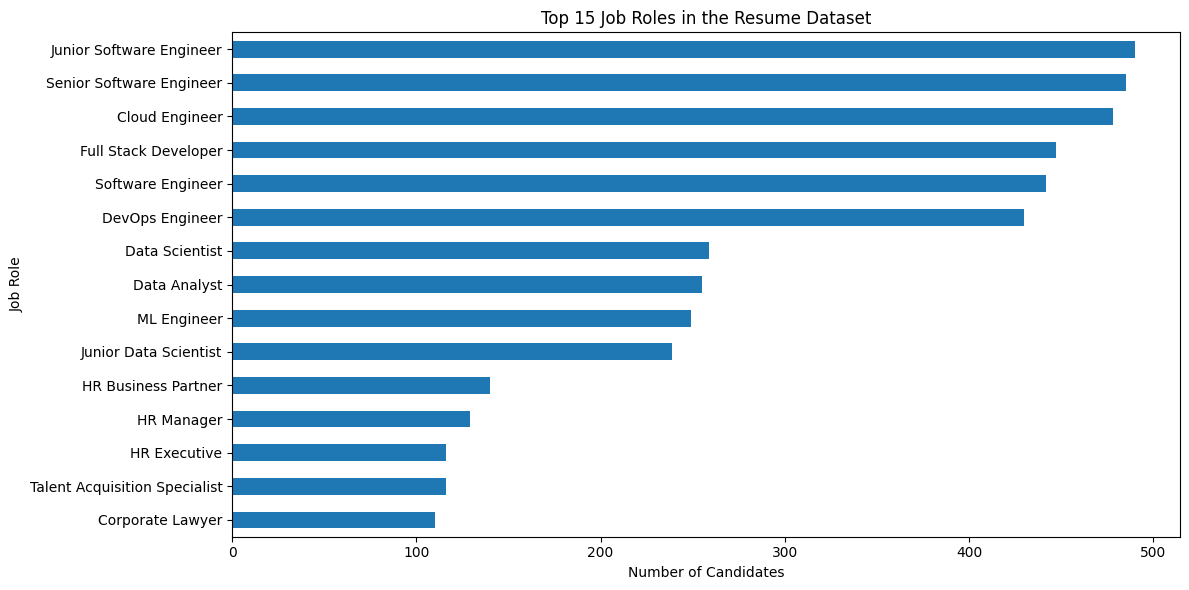

In [ ]:
# Top 15 job roles
top_roles = df["primary_role"].fillna("Unknown").value_counts().head(15)

plt.figure(figsize=(12, 6))
top_roles.sort_values().plot(kind="barh")
plt.title("Top 15 Job Roles in the Resume Dataset")
plt.xlabel("Number of Candidates")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

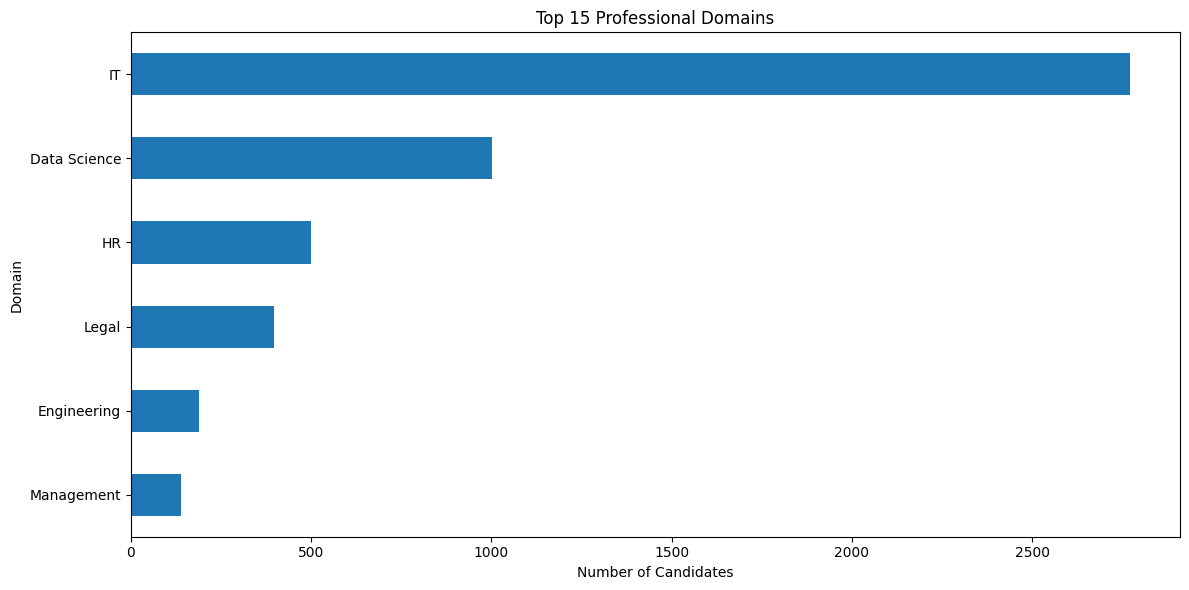

In [ ]:
top_domains = df["primary_domain"].fillna("Unknown").value_counts().head(15)

plt.figure(figsize=(12, 6))
top_domains.sort_values().plot(kind="barh")
plt.title("Top 15 Professional Domains")
plt.xlabel("Number of Candidates")
plt.ylabel("Domain")
plt.tight_layout()
plt.show()

Experience statistics:


,years_experience
count,5000.000000
mean,6.733600
std,4.026645
min,1.000000
25%,4.000000
50%,6.000000
75%,9.000000
max,20.000000


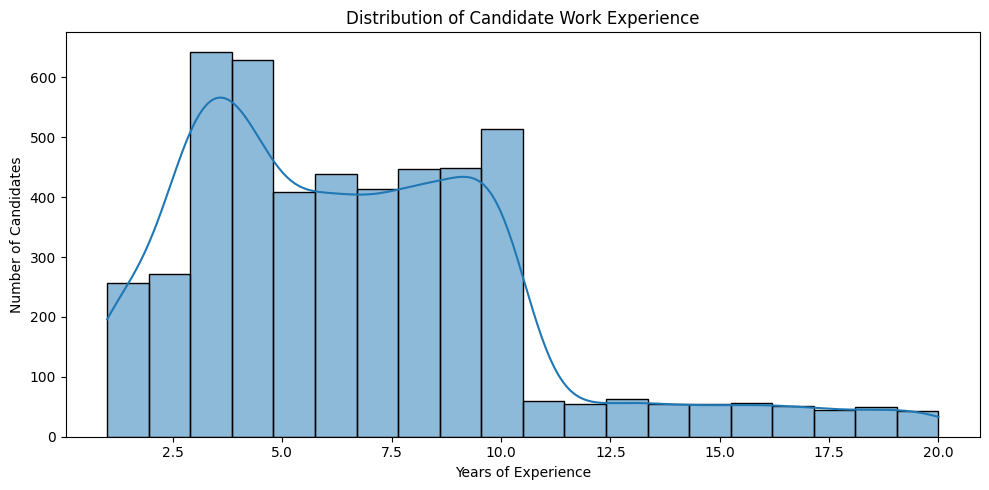

In [ ]:
# Convert experience to numeric, if necessary
df["years_experience"] = pd.to_numeric(
    df["years_experience"], errors="coerce"
)

print("Experience statistics:")
display(df["years_experience"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="years_experience",
    bins=20,
    kde=True
)
plt.title("Distribution of Candidate Work Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.show()

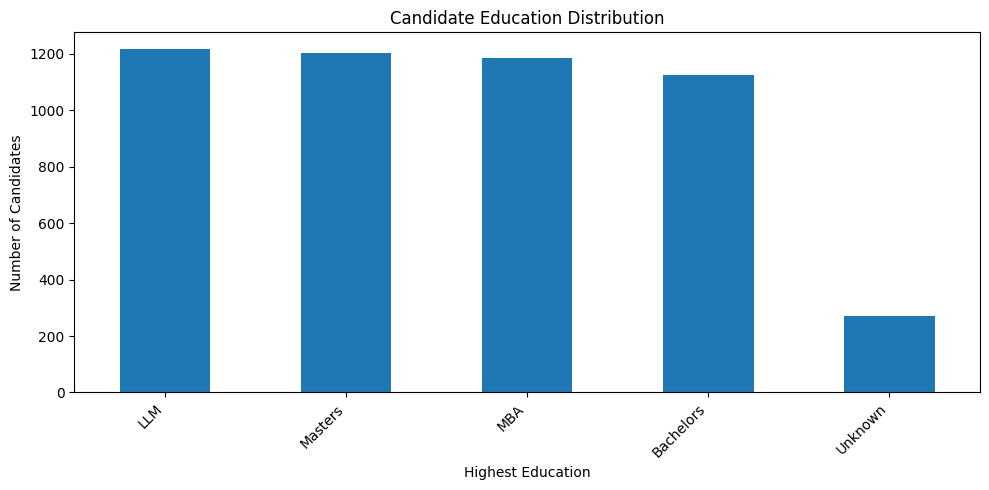

In [ ]:
education_counts = (
    df["highest_education"]
    .fillna("Unknown")
    .value_counts()
)

plt.figure(figsize=(10, 5))
education_counts.plot(kind="bar")
plt.title("Candidate Education Distribution")
plt.xlabel("Highest Education")
plt.ylabel("Number of Candidates")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

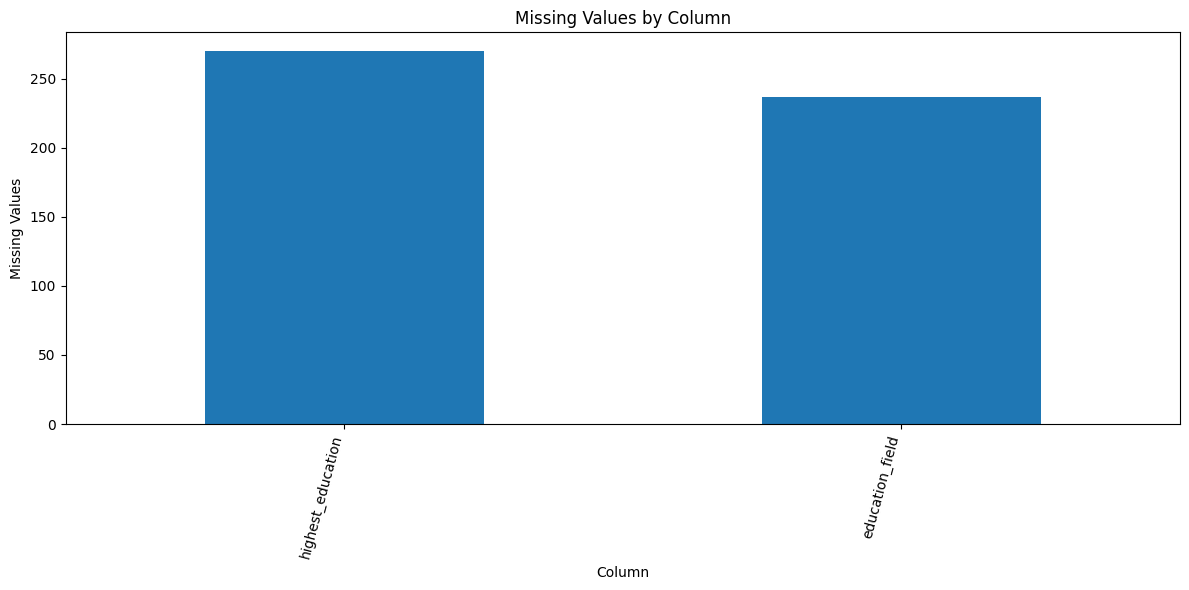

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    plt.figure(figsize=(12, 6))
    missing.plot(kind="bar")
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Values")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")

In [ ]:
flag_columns = [
    col for col in df.columns
    if col.endswith("_flag")
]

for col in flag_columns[:8]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


management_experience_flag
management_experience_flag
0    3059
1    1941
Name: count, dtype: int64

people_management_flag
people_management_flag
0    3954
1    1046
Name: count, dtype: int64

project_management_experience_flag
project_management_experience_flag
1    3200
0    1800
Name: count, dtype: int64

agile_scrum_experience_flag
agile_scrum_experience_flag
1    3913
0    1087
Name: count, dtype: int64

client_facing_experience_flag
client_facing_experience_flag
1    3829
0    1171
Name: count, dtype: int64

delivery_lead_experience_flag
delivery_lead_experience_flag
0    3506
1    1494
Name: count, dtype: int64

cloud_experience_flag
cloud_experience_flag
0    3612
1    1388
Name: count, dtype: int64

ml_experience_flag
ml_experience_flag
0    3998
1    1002
Name: count, dtype: int64


In [ ]:
for col in [
    "resume_length_words",
    "keyword_density_score",
    "profile_completeness_score"
]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

display(
    df[
        [
            "resume_length_words",
            "keyword_density_score",
            "profile_completeness_score"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
resume_length_words,5000.0,54.850600,2.887897,48.00,53.00,55.00,57.00,63.00
keyword_density_score,5000.0,0.577590,0.187424,0.25,0.42,0.58,0.74,0.90
profile_completeness_score,5000.0,0.751524,0.115454,0.55,0.65,0.75,0.85,0.95


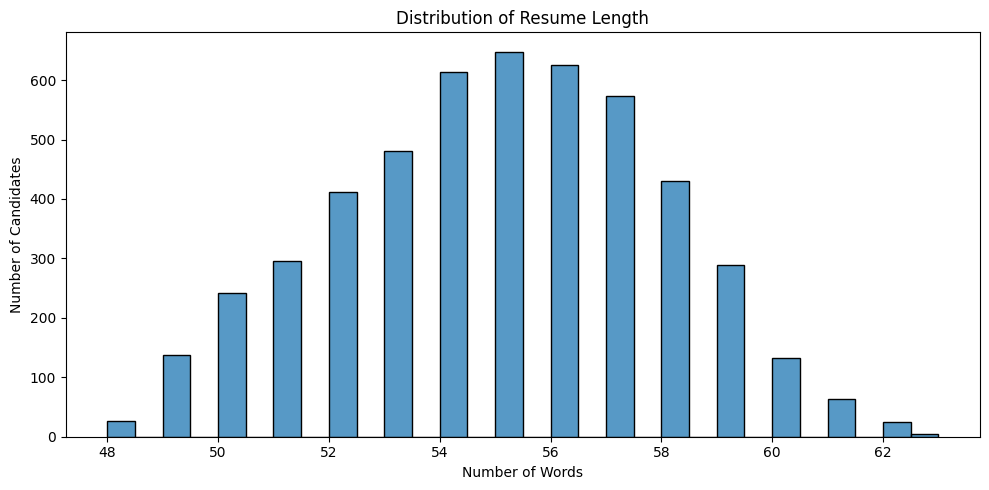

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="resume_length_words",
    bins=30
)
plt.title("Distribution of Resume Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import re

df = pd.read_csv("parsed_resumes_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5000, 34)


,candidate_id,resume_file_name,candidate_name,primary_domain,primary_role,years_experience,highest_education,education_field,institution_tier,technical_skills_raw,...,enterprise_systems_experience_flag,offshore_onsite_model_experience_flag,multi_vendor_coordination_flag,process_compliance_experience_flag,documentation_heavy_role_flag,mentoring_experience_flag,stakeholder_management_experience_flag,resume_length_words,keyword_density_score,profile_completeness_score
0,CND_100001,DataAnalyst_1.pdf,Candidate_1,Data Science,Data Analyst,7,LLM,Mathematics,Tier-1,"Machine Learning, Power BI, Pandas, Python",...,1,1,1,1,0,1,1,56,0.74,0.61
1,CND_100002,profile_2.pdf,Candidate_2,IT,Senior Software Engineer,10,Masters,Computer Science,Tier-2,"Kubernetes, Git, Docker, Python",...,1,1,1,1,1,1,1,54,0.89,0.89
2,CND_100003,Legal_candidate_3.pdf,Candidate_3,Legal,Compliance Officer,7,LLM,Law,Tier-1,"Due Diligence, Legal Research, Compliance, Con...",...,1,1,1,1,1,1,1,57,0.40,0.56
3,CND_100004,IT_candidate_4.pdf,Candidate_4,IT,Senior Software Engineer,9,LLM,Computer Science,Tier-1,"Kubernetes, AWS, SQL, Docker",...,1,1,1,1,1,1,1,55,0.74,0.89
4,CND_100005,IT_candidate_5.pdf,Candidate_5,IT,Software Engineer,9,Masters,Information Technology,Tier-1,"Java, Kubernetes, Git, AWS",...,1,1,1,1,1,1,1,51,0.58,0.59


In [ ]:
text_columns = [
    "technical_skills_raw",
    "tools_platforms_raw",
    "soft_skills_raw",
    "experience_summary",
    "project_summary",
    "key_achievements"
]

# Check that all required columns exist
missing_columns = [
    col for col in text_columns if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required text columns are available.")

All required text columns are available.


In [ ]:
for col in text_columns:
    df[col] = df[col].fillna("").astype(str).str.strip()

print("Missing values after cleaning:")
display(df[text_columns].isnull().sum())

Missing values after cleaning:


,0
technical_skills_raw,0
tools_platforms_raw,0
soft_skills_raw,0
experience_summary,0
project_summary,0
key_achievements,0


In [ ]:
def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b", " ", text)

    # Keep letters, numbers, whitespace, +, #, and periods
    # This helps preserve terms such as C++, C#, and .NET
    text = re.sub(r"[^a-z0-9\s+#.]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
df["combined_text"] = df[text_columns].agg(" ".join, axis=1)

df["cleaned_text"] = df["combined_text"].apply(clean_text)

display(
    df[
        ["candidate_id", "combined_text", "cleaned_text"]
    ].head(5)
)

,candidate_id,combined_text,cleaned_text
0,CND_100001,"Machine Learning, Power BI, Pandas, Python AWS...",machine learning power bi pandas python aws se...
1,CND_100002,"Kubernetes, Git, Docker, Python AWS, Jira Team...",kubernetes git docker python aws jira teamwork...
2,CND_100003,"Due Diligence, Legal Research, Compliance, Con...",due diligence legal research compliance contra...
3,CND_100004,"Kubernetes, AWS, SQL, Docker Azure, GCP Leader...",kubernetes aws sql docker azure gcp leadership...
4,CND_100005,"Java, Kubernetes, Git, AWS AWS, ServiceNow Tea...",java kubernetes git aws aws servicenow teamwor...


In [ ]:
# Identify records with no usable text
empty_text_count = df["cleaned_text"].str.strip().eq("").sum()

# Calculate the number of words in cleaned text
df["cleaned_text_word_count"] = (
    df["cleaned_text"].str.split().str.len()
)

print("Records with empty cleaned text:", empty_text_count)

display(
    df["cleaned_text_word_count"].describe()
)

Records with empty cleaned text: 0


,cleaned_text_word_count
count,5000.000000
mean,56.505000
std,2.731422
min,50.000000
25%,55.000000
50%,57.000000
75%,58.000000
max,64.000000


In [ ]:
output_file = "parsed_resumes_nlp_prepared.csv"

df.to_csv(output_file, index=False)

print("Saved:", output_file)
print("Final dataset shape:", df.shape)

Saved: parsed_resumes_nlp_prepared.csv
Final dataset shape: (5000, 37)


## Import the required libraries

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("parsed_resumes_nlp_prepared.csv")

# Check the required column
if "cleaned_text" not in df.columns:
    raise ValueError(
        "cleaned_text is missing. Complete Step 4 first."
    )

df["cleaned_text"] = df["cleaned_text"].fillna("").astype(str)

# Remove records with no usable text for this analysis
resume_texts = df["cleaned_text"].str.strip()
valid_mask = resume_texts.ne("")

resume_df = df.loc[valid_mask].copy()
resume_texts = resume_df["cleaned_text"].tolist()

print("Total records:", len(df))
print("Records with usable text:", len(resume_df))

Total records: 5000
Records with usable text: 5000


In [ ]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

resume_tfidf = tfidf_vectorizer.fit_transform(resume_texts)

print("TF-IDF matrix shape:", resume_tfidf.shape)
print("Number of resumes:", resume_tfidf.shape[0])
print("Number of text features:", resume_tfidf.shape[1])

TF-IDF matrix shape: (5000, 2216)
Number of resumes: 5000
Number of text features: 2216


In [ ]:
feature_names = tfidf_vectorizer.get_feature_names_out()

# Inspect the highest-weight terms for the first usable resume
first_vector = resume_tfidf[0].toarray().ravel()
top_indices = first_vector.argsort()[-15:][::-1]

top_terms = pd.DataFrame({
    "Term": feature_names[top_indices],
    "TF_IDF_Score": first_vector[top_indices]
})

display(top_terms)

,Term,TF_IDF_Score
0,learning power,0.207503
1,bi pandas,0.203333
2,pandas python,0.200088
3,servicenow leadership,0.171465
4,by and,0.165129
5,aws servicenow,0.157923
6,python aws,0.155903
7,leadership teamwork,0.153673
8,teamwork hands,0.146239
9,science professional,0.142593


In [ ]:
role_profiles = {
    "Data Scientist": """
        Python SQL machine learning statistics
        data analysis feature engineering model evaluation
        predictive modeling scikit-learn pandas numpy
        data visualization experiments
    """,

    "Data Analyst": """
        SQL Excel Python Power BI Tableau
        data cleaning reporting dashboards
        business intelligence data visualization
        statistical analysis business insights
    """,

    "Software Developer": """
        programming software development algorithms
        data structures object oriented programming
        APIs debugging testing Git
        application development Python Java C++
    """
}

roles = list(role_profiles.keys())
role_descriptions = list(role_profiles.values())

print("Role profiles:", roles)

Role profiles: ['Data Scientist', 'Data Analyst', 'Software Developer']


In [ ]:
all_texts = resume_texts + role_descriptions

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

all_tfidf = tfidf_vectorizer.fit_transform(all_texts)

# Separate resume vectors from role-profile vectors
n_resumes = len(resume_texts)

resume_tfidf = all_tfidf[:n_resumes]
role_tfidf = all_tfidf[n_resumes:]

print("Resume matrix:", resume_tfidf.shape)
print("Role matrix:", role_tfidf.shape)

Resume matrix: (5000, 2289)
Role matrix: (3, 2289)


In [ ]:
similarity_matrix = cosine_similarity(
    resume_tfidf,
    role_tfidf
)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (5000, 3)


In [ ]:
candidate_index = 0

scores = similarity_matrix[candidate_index]

candidate_matches = pd.DataFrame({
    "Role": roles,
    "Similarity_Score": scores
})

candidate_matches = candidate_matches.sort_values(
    "Similarity_Score",
    ascending=False
).reset_index(drop=True)

display(candidate_matches)

,Role,Similarity_Score
0,Data Scientist,0.046732
1,Data Analyst,0.040042
2,Software Developer,0.019314


In [ ]:
candidate_id = resume_df.iloc[candidate_index]["candidate_id"]

print("Candidate ID:", candidate_id)
print("Ranked role matches:")

display(candidate_matches)

Candidate ID: CND_100001
Ranked role matches:


,Role,Similarity_Score
0,Data Scientist,0.046732
1,Data Analyst,0.040042
2,Software Developer,0.019314


In [ ]:
selected_role = "Data Scientist"
role_index = roles.index(selected_role)

role_scores = similarity_matrix[:, role_index]

ranked_candidates = resume_df[
    ["candidate_id", "candidate_name", "primary_role",
     "years_experience"]
].copy()

ranked_candidates["Similarity_Score"] = role_scores

ranked_candidates = ranked_candidates.sort_values(
    "Similarity_Score",
    ascending=False
).reset_index(drop=True)

display(ranked_candidates.head(10))

,candidate_id,candidate_name,primary_role,years_experience,Similarity_Score
0,CND_100090,Candidate_90,Junior Data Scientist,1,0.084062
1,CND_101846,Candidate_1846,Data Scientist,8,0.083911
2,CND_101942,Candidate_1942,Data Scientist,3,0.081094
3,CND_100055,Candidate_55,Junior Data Scientist,3,0.080566
4,CND_100356,Candidate_356,Data Analyst,9,0.080121
5,CND_101287,Candidate_1287,Data Scientist,9,0.079659
6,CND_101733,Candidate_1733,Data Scientist,6,0.079180
7,CND_104160,Candidate_4160,ML Engineer,3,0.078670
8,CND_103387,Candidate_3387,Data Scientist,7,0.077855
9,CND_103861,Candidate_3861,Data Scientist,6,0.076952


In [ ]:
# Save the resume-to-role similarity scores
score_columns = [
    f"{role}_similarity".replace(" ", "_").lower()
    for role in roles
]

scores_df = pd.DataFrame(
    similarity_matrix,
    columns=score_columns,
    index=resume_df.index
)

results = resume_df[
    ["candidate_id", "candidate_name", "primary_role"]
].join(scores_df)

results.to_csv("resume_role_similarity_scores.csv", index=False)

print("Saved resume_role_similarity_scores.csv")

Saved resume_role_similarity_scores.csv


In [ ]:
role_requirements = {
    "Data Scientist": {
        "skills": [
            "python", "sql", "machine learning",
            "statistics", "pandas", "scikit-learn"
        ],
        "min_experience": 2
    },
    "Data Analyst": {
        "skills": [
            "sql", "excel", "python",
            "power bi", "tableau", "data visualization"
        ],
        "min_experience": 1
    },
    "Software Developer": {
        "skills": [
            "python", "java", "c++",
            "data structures", "algorithms", "git"
        ],
        "min_experience": 1
    }
}

print("Roles defined:", list(role_requirements.keys()))

Roles defined: ['Data Scientist', 'Data Analyst', 'Software Developer']


In [ ]:
import re
import pandas as pd
import numpy as np

def contains_skill(text, skill):
    # Match the complete phrase, not just part of a longer word
    pattern = r"(?<!\w)" + re.escape(skill.lower()) + r"(?!\w)"
    return bool(re.search(pattern, text.lower()))

def calculate_skill_coverage(text, required_skills):
    if not required_skills:
        return np.nan

    matched = sum(
        contains_skill(text, skill)
        for skill in required_skills
    )

    return matched / len(required_skills)

# Example for the first resume
example_text = resume_df.iloc[0]["cleaned_text"]
example_skills = role_requirements["Data Scientist"]["skills"]

coverage = calculate_skill_coverage(
    example_text,
    example_skills
)

print("Skill coverage:", round(coverage * 100, 2), "%")

Skill coverage: 50.0 %


In [ ]:
def calculate_experience_fit(years, minimum_years):
    if pd.isna(years):
        return np.nan

    years = max(float(years), 0)

    if minimum_years <= 0:
        return 1.0

    return min(years / minimum_years, 1.0)

print(
    "Example experience fit:",
    calculate_experience_fit(1, 2)
)

Example experience fit: 0.5


In [ ]:
# Ensure these variables from Step 5 are available:
# resume_df, similarity_matrix, roles

results = []

for i, (_, resume) in enumerate(resume_df.iterrows()):
    text = str(resume["cleaned_text"])

    for j, role in enumerate(roles):
        requirements = role_requirements[role]

        text_score = float(similarity_matrix[i, j])

        skill_score = calculate_skill_coverage(
            text,
            requirements["skills"]
        )

        years = pd.to_numeric(
            pd.Series([resume.get("years_experience", np.nan)]),
            errors="coerce"
        ).iloc[0]

        experience_score = calculate_experience_fit(
            years,
            requirements["min_experience"]
        )

        # Use available components only and rescale weights
        components = [
            (text_score, 0.50),
            (skill_score, 0.30),
            (experience_score, 0.20)
        ]

        available = [
            (score, weight)
            for score, weight in components
            if pd.notna(score)
        ]

        denominator = sum(weight for _, weight in available)

        composite_score = (
            sum(score * weight for score, weight in available)
            / denominator
            * 100
        )

        results.append({
            "candidate_id": resume["candidate_id"],
            "candidate_name": resume.get("candidate_name", ""),
            "role": role,
            "text_similarity": text_score,
            "skill_coverage": skill_score,
            "experience_fit": experience_score,
            "composite_score": composite_score
        })

matching_df = pd.DataFrame(results)

display(matching_df.head())

,candidate_id,candidate_name,role,text_similarity,skill_coverage,experience_fit,composite_score
0,CND_100001,Candidate_1,Data Scientist,0.046732,0.500000,1.0,37.336598
1,CND_100001,Candidate_1,Data Analyst,0.040042,0.333333,1.0,32.002078
2,CND_100001,Candidate_1,Software Developer,0.019314,0.166667,1.0,25.965686
3,CND_100002,Candidate_2,Data Scientist,0.003371,0.166667,1.0,25.168546
4,CND_100002,Candidate_2,Data Analyst,0.010064,0.166667,1.0,25.503191


In [ ]:
selected_role = "Data Scientist"

ranked_candidates = (
    matching_df[matching_df["role"] == selected_role]
    .sort_values("composite_score", ascending=False)
    .reset_index(drop=True)
)

display(
    ranked_candidates[
        [
            "candidate_id",
            "role",
            "text_similarity",
            "skill_coverage",
            "experience_fit",
            "composite_score"
        ]
    ].head(10)
)

,candidate_id,role,text_similarity,skill_coverage,experience_fit,composite_score
0,CND_101287,Data Scientist,0.079659,0.666667,1.0,43.982952
1,CND_103861,Data Scientist,0.076952,0.666667,1.0,43.847583
2,CND_101328,Data Scientist,0.070919,0.666667,1.0,43.545950
3,CND_102286,Data Scientist,0.070394,0.666667,1.0,43.519710
4,CND_100918,Data Scientist,0.067461,0.666667,1.0,43.373043
5,CND_100731,Data Scientist,0.066074,0.666667,1.0,43.303712
6,CND_102529,Data Scientist,0.062229,0.666667,1.0,43.111453
7,CND_104427,Data Scientist,0.057429,0.666667,1.0,42.871451
8,CND_100330,Data Scientist,0.055874,0.666667,1.0,42.793718
9,CND_102151,Data Scientist,0.054451,0.666667,1.0,42.722540


In [ ]:
def explain_match(candidate_id, role):
    rows = matching_df[
        (matching_df["candidate_id"] == candidate_id)
        & (matching_df["role"] == role)
    ]

    if rows.empty:
        print("Candidate or role not found.")
        return

    result = rows.iloc[0]

    print("Candidate ID:", result["candidate_id"])
    print("Role:", result["role"])
    print("Composite score:", round(result["composite_score"], 2))
    print("Text similarity:", round(result["text_similarity"], 3))

    if pd.notna(result["skill_coverage"]):
        print(
            "Skill coverage:",
            round(result["skill_coverage"] * 100, 2), "%"
        )
    else:
        print("Skill coverage: unavailable")

    if pd.notna(result["experience_fit"]):
        print(
            "Experience fit:",
            round(result["experience_fit"] * 100, 2), "%"
        )
    else:
        print("Experience fit: unavailable")

# Example: explain the top-ranked match
top_candidate_id = ranked_candidates.iloc[0]["candidate_id"]
explain_match(top_candidate_id, selected_role)

Candidate ID: CND_101287
Role: Data Scientist
Composite score: 43.98
Text similarity: 0.08
Skill coverage: 66.67 %
Experience fit: 100.0 %


In [ ]:
matching_df.to_csv(
    "resume_role_composite_matching_results.csv",
    index=False
)

print("Matching results saved successfully.")
print("Total resume-role comparisons:", len(matching_df))

Matching results saved successfully.
Total resume-role comparisons: 15000


In [ ]:
import pandas as pd

labels = pd.read_csv("resume_role_labels.csv")

required_columns = {"candidate_id", "role", "relevant"}

if not required_columns.issubset(labels.columns):
    raise ValueError(
        f"Labels must contain: {required_columns}"
    )

labels["relevant"] = pd.to_numeric(
    labels["relevant"], errors="raise"
)

if not labels["relevant"].isin([0, 1]).all():
    raise ValueError("relevant must contain only 0 or 1.")

if labels.duplicated(["candidate_id", "role"]).any():
    raise ValueError(
        "Duplicate candidate_id-role pairs found."
    )

print("Labelled pairs:", len(labels))
print("Relevant pairs:", int(labels["relevant"].sum()))
print("Non-relevant pairs:", int((labels["relevant"] == 0).sum()))

Labelled pairs: 3429
Relevant pairs: 7
Non-relevant pairs: 3422


In [ ]:
evaluation_df = labels.merge(
    matching_df[
        ["candidate_id", "role", "composite_score"]
    ],
    on=["candidate_id", "role"],
    how="left",
    validate="one_to_one"
)

if evaluation_df["composite_score"].isna().any():
    missing = evaluation_df[
        evaluation_df["composite_score"].isna()
    ]
    print("Some labelled pairs have no matching score:")
    display(missing.head())

evaluation_df = evaluation_df.dropna(
    subset=["composite_score"]
)

print("Pairs available for evaluation:", len(evaluation_df))
display(evaluation_df.head())

Pairs available for evaluation: 3429


,candidate_id,role,relevant,composite_score
0,CND_100001,Data Scientist,0,37.336598
1,CND_100001,Data Analyst,0,32.002078
2,CND_100001,Software Developer,0,25.965686
3,CND_100002,Data Scientist,0,25.168546
4,CND_100002,Data Analyst,0,25.503191


In [ ]:
print("Labels columns:")
print(labels.columns.tolist())

print("\nMatching results columns:")
print(matching_df.columns.tolist())

Labels columns:
['candidate_id', 'role', 'relevant']

Matching results columns:
['candidate_id', 'candidate_name', 'role', 'text_similarity', 'skill_coverage', 'experience_fit', 'composite_score']


In [ ]:
import pandas as pd

matching_df = pd.read_csv(
    "resume_role_composite_matching_results.csv"
)

print("Columns in your file:")
print(matching_df.columns.tolist())

display(matching_df.head())

Columns in your file:
['candidate_id', 'candidate_name', 'role', 'text_similarity', 'skill_coverage', 'experience_fit', 'composite_score']


,candidate_id,candidate_name,role,text_similarity,skill_coverage,experience_fit,composite_score
0,CND_100001,Candidate_1,Data Scientist,0.046732,0.500000,1.0,37.336598
1,CND_100001,Candidate_1,Data Analyst,0.040042,0.333333,1.0,32.002078
2,CND_100001,Candidate_1,Software Developer,0.019314,0.166667,1.0,25.965686
3,CND_100002,Candidate_2,Data Scientist,0.003371,0.166667,1.0,25.168546
4,CND_100002,Candidate_2,Data Analyst,0.010064,0.166667,1.0,25.503191


In [ ]:
def precision_recall_at_k(group, k=10):
    group = group.sort_values(
        "composite_score", ascending=False
    )

    top_k = group.head(k)
    relevant_total = int(group["relevant"].sum())

    precision = (
        top_k["relevant"].sum() / len(top_k)
        if len(top_k) else 0.0
    )

    recall = (
        top_k["relevant"].sum() / relevant_total
        if relevant_total else float("nan")
    )

    return pd.Series({
        f"Precision@{k}": precision,
        f"Recall@{k}": recall,
        "Evaluated candidates": len(group),
        "Relevant candidates": relevant_total
    })

k = 10

metrics_by_role = (
    evaluation_df.groupby("role", group_keys=False)
    .apply(precision_recall_at_k, k=k)
    .reset_index()
)

display(metrics_by_role)

,role,Precision@10,Recall@10,Evaluated candidates,Relevant candidates
0,Data Analyst,0.0,NaN,1144.0,0.0
1,Data Scientist,0.7,1.0,1143.0,7.0
2,Software Developer,0.0,NaN,1142.0,0.0


In [ ]:
import numpy as np
from sklearn.metrics import ndcg_score

def calculate_ndcg(group, k=10):
    group = group.sort_values(
        "composite_score", ascending=False
    )

    relevance = group["relevant"].to_numpy()

    if len(relevance) == 0 or relevance.sum() == 0:
        return np.nan

    # One row: relevance labels in predicted ranking order
    return ndcg_score(
        [relevance],
        [np.arange(len(relevance), 0, -1)],
        k=min(k, len(relevance))
    )

ndcg_results = []

for role, group in evaluation_df.groupby("role"):
    ndcg_results.append({
        "role": role,
        "NDCG@10": calculate_ndcg(group, k=10)
    })

ndcg_df = pd.DataFrame(ndcg_results)
display(ndcg_df)

,role,NDCG@10
0,Data Analyst,NaN
1,Data Scientist,1.0
2,Software Developer,NaN


In [ ]:
from sklearn.metrics import ndcg_score
import pandas as pd
import numpy as np

# Ensure evaluation_df contains 'text_similarity' from matching_df
if "text_similarity" not in evaluation_df.columns and "matching_df" in globals():
    evaluation_df = evaluation_df.merge(
        matching_df[["candidate_id", "role", "text_similarity"]],
        on=["candidate_id", "role"],
        how="left"
    )

def ranking_ndcg(group, score_column, k=10):
    group = group.sort_values(
        score_column, ascending=False
    )

    relevance = group["relevant"].to_numpy()

    if len(relevance) == 0 or relevance.sum() == 0:
        return np.nan

    return ndcg_score(
        [relevance],
        [group[score_column].to_numpy()],
        k=min(k, len(group))
    )

comparison = []

for role, group in evaluation_df.groupby("role"):
    comparison.append({
        "role": role,
        "TF-IDF NDCG@10": ranking_ndcg(
            group, "text_similarity", 10
        ),
        "Composite NDCG@10": ranking_ndcg(
            group, "composite_score", 10
        )
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,role,TF-IDF NDCG@10,Composite NDCG@10
0,Data Analyst,NaN,NaN
1,Data Scientist,0.079457,1.0
2,Software Developer,NaN,NaN


In [ ]:
import pandas as pd
from google.colab import files

# Load the matching results
matching_df = pd.read_csv(
    "resume_role_composite_matching_results.csv"
)

# Clean column names
matching_df.columns = matching_df.columns.str.strip()

# Add relevance based on the 40-point threshold
matching_df["relevant"] = (
    matching_df["composite_score"] > 40
).astype(int)

# Save the final results
matching_df.to_csv(
    "resume_role_composite_matching_results.csv",
    index=False
)

print("Final matching results saved successfully!")
print("Total rows:", len(matching_df))
print("Relevant (1):", int(matching_df["relevant"].sum()))
print("Not relevant (0):", int((matching_df["relevant"] == 0).sum()))

display(matching_df.head(10))

Final matching results saved successfully!
Total rows: 15000
Relevant (1): 20
Not relevant (0): 14980


,candidate_id,candidate_name,role,text_similarity,skill_coverage,experience_fit,composite_score,relevant
0,CND_100001,Candidate_1,Data Scientist,0.046732,0.500000,1.0,37.336598,0
1,CND_100001,Candidate_1,Data Analyst,0.040042,0.333333,1.0,32.002078,0
2,CND_100001,Candidate_1,Software Developer,0.019314,0.166667,1.0,25.965686,0
3,CND_100002,Candidate_2,Data Scientist,0.003371,0.166667,1.0,25.168546,0
4,CND_100002,Candidate_2,Data Analyst,0.010064,0.166667,1.0,25.503191,0
5,CND_100002,Candidate_2,Software Developer,0.007945,0.333333,1.0,30.397243,0
6,CND_100003,Candidate_3,Data Scientist,0.000000,0.000000,1.0,20.000000,0
7,CND_100003,Candidate_3,Data Analyst,0.000000,0.000000,1.0,20.000000,0
8,CND_100003,Candidate_3,Software Developer,0.009198,0.000000,1.0,20.459882,0
9,CND_100004,Candidate_4,Data Scientist,0.003148,0.166667,1.0,25.157408,0


In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Keep only pairs with valid human labels and scores
evaluation_df = evaluation_df.dropna(
    subset=["relevant", "composite_score"]
).copy()

evaluation_df["relevant"] = pd.to_numeric(
    evaluation_df["relevant"], errors="raise"
).astype(int)

evaluation_df["predicted_relevant"] = (
    evaluation_df["composite_score"] > 40
).astype(int)

y_true = evaluation_df["relevant"]
y_pred = evaluation_df["predicted_relevant"]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, zero_division=0),
        recall_score(y_true, y_pred, zero_division=0),
        f1_score(y_true, y_pred, zero_division=0)
    ]
})

metrics.to_csv("resume_matching_evaluation_metrics.csv", index=False)

display(metrics)

,Metric,Value
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1-score,1.0


In [ ]:
files.download(
    "resume_role_composite_matching_results.csv"
)

# Run this only if Section 8.2 completed successfully
files.download(
    "resume_matching_evaluation_metrics.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>